# Pemodelan dan Simulasi Sistem Dinamik: Konsentrasi Kafein dalam Darah Setelah Minum Kopi
**Model Kompartemen Absorpsi dan Eliminasi Orde Satu**

* **Nama Mahasiswa:** Sigit Miraj Permana
* **NIM:** 301240037
* **Program Studi:** Teknik Informatika — Fakultas Teknologi Informasi, Universitas Bale Bandung (UNIBBA)
* **Mata Kuliah:** Pemodelan dan Simulasi


## 1. Deskripsi Studi Kasus & Formulasi Matematis

Kafein merupakan senyawa alkaloid psikoaktif yang banyak dikonsumsi melalui minuman kopi. Setelah dikonsumsi secara oral, kafein tidak langsung berada seluruhnya di dalam aliran darah, melainkan melewati dua tahapan dinamik utama:
1. **Fase Absorpsi ($A_{\text{gut}}$):** Penyerapan kafein dari saluran pencernaan (lambung dan usus halus) menuju sirkulasi sistemik dengan laju proporsional terhadap sisa massa kafein di saluran cerna ($k_a$).
2. **Fase Eliminasi ($C(t)$):** Metabolisme kafein di organ hati (terutama oleh enzim CYP1A2) dan ekskresi melalui ginjal dengan laju proporsional terhadap konsentrasi kafein dalam plasma darah ($k_e$).

### Sistem Persamaan Diferensial Biasa (ODE)
$$\frac{dA_{\text{gut}}(t)}{dt} = -k_a \cdot A_{\text{gut}}(t)$$

$$\frac{dC(t)}{dt} = \frac{k_a \cdot A_{\text{gut}}(t)}{V_d} - k_e \cdot C(t)$$

### Solusi Analitik (Persamaan Bateman)
Dengan kondisi awal $A_{\text{gut}}(0) = F \cdot D$ dan $C(0) = 0$:
$$A_{\text{gut}}(t) = (F \cdot D) e^{-k_a t}$$
$$C(t) = \frac{F \cdot D \cdot k_a}{V_d (k_a - k_e)} \left( e^{-k_e t} - e^{-k_a t} \right)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import pandas as pd

# Konfigurasi tampilan grafik
plt.rcParams['figure.dpi'] = 120
print("Library berhasil dimuat!")

Library berhasil dimuat!


## 2. Inisialisasi Parameter Farmakokinetik Kafein
Berdasarkan literatur farmakokinetik klinis untuk konsumsi **1 cangkir kopi seduh ($\pm 240\text{ mL}$)** pada individu dewasa sehat (berat badan $70\text{ kg}$):
* **Dosis Kafein ($D$):** $100\text{ mg}$
* **Bioavailabilitas Oral ($F$):** $0,99$ ($99\%$)
* **Volume Distribusi ($V_d$):** $42,0\text{ Liter}$ ($0,6\text{ L/kg} \times 70\text{ kg}$)
* **Konstanta Laju Absorpsi ($k_a$):** $3,0\text{ jam}^{-1}$
* **Waktu Paruh Eliminasi ($t_{1/2}$):** $5,0\text{ jam}$
* **Konstanta Laju Eliminasi ($k_e$):** $\frac{\ln(2)}{t_{1/2}} \approx 0,138629\text{ jam}^{-1}$

In [2]:
# Definisi Parameter Farmakokinetik
D = 100.0                 # Dosis kafein (mg)
F = 0.99                  # Bioavailabilitas oral (99%)
Vd = 42.0                 # Volume distribusi (Liter)
ka = 3.0                  # Konstanta laju absorpsi (jam^-1)
t_half = 5.0              # Waktu paruh eliminasi (jam)
ke = np.log(2) / t_half   # Konstanta laju eliminasi (jam^-1)

# Kondisi Awal
A0 = F * D                # Massa awal kafein di saluran cerna (99.0 mg)
C0 = 0.0                  # Konsentrasi awal kafein di plasma darah (0.0 mg/L)
y0 = [A0, C0]

# Perhitungan Titik Puncak Teoretis (Tmax dan Cmax)
t_max = np.log(ka / ke) / (ka - ke)
c_max = ((F * D * ka) / (Vd * (ka - ke))) * (np.exp(-ke * t_max) - np.exp(-ka * t_max))

print(f"Konstanta Eliminasi (ke)   : {ke:.6f} jam^-1")
print(f"Waktu Puncak (T_max)       : {t_max:.4f} jam ({t_max*60:.1f} menit)")
print(f"Konsentrasi Puncak (C_max) : {c_max:.4f} mg/L")

Konstanta Eliminasi (ke)   : 0.138629 jam^-1
Waktu Puncak (T_max)       : 1.0745 jam (64.5 menit)
Konsentrasi Puncak (C_max) : 2.0309 mg/L


## 3. Implementasi Model ODE & Simulasi Numerik (`odeint`)

In [3]:
# Fungsi sistem persamaan diferensial dua kompartemen
def model_kafein(y, t, ka, ke, Vd):
    A_gut, C_plasma = y
    dAgut_dt = -ka * A_gut
    dCplasma_dt = (ka * A_gut) / Vd - ke * C_plasma
    return [dAgut_dt, dCplasma_dt]

# Fungsi solusi analitik (untuk validasi perhitungan manual)
def analitik_kafein(t, D, F, ka, ke, Vd):
    A_gut = (F * D) * np.exp(-ka * t)
    C_plasma = ((F * D * ka) / (Vd * (ka - ke))) * (np.exp(-ke * t) - np.exp(-ka * t))
    return A_gut, C_plasma

# Rentang waktu simulasi 0 hingga 24 jam (interval 0.05 jam)
t = np.linspace(0, 24, 481)

# Eksekusi solver ODEINT
sol_numerik = odeint(model_kafein, y0, t, args=(ka, ke, Vd))
A_num = sol_numerik[:, 0]
C_num = sol_numerik[:, 1]

# Hitung solusi analitik pada seluruh titik waktu
A_ana, C_ana = analitik_kafein(t, D, F, ka, ke, Vd)
print("Simulasi numerik ODEINT selesai dijalankan.")

Simulasi numerik ODEINT selesai dijalankan.


## 4. Tabel Validasi Perhitungan Manual vs Simulasi Python (`odeint`)

In [4]:
# Titik waktu evaluasi setiap 2 jam
t_cek = np.arange(0, 25, 2, dtype=float)
sol_cek = odeint(model_kafein, y0, t_cek, args=(ka, ke, Vd))
A_ana_cek, C_ana_cek = analitik_kafein(t_cek, D, F, ka, ke, Vd)

df_validasi = pd.DataFrame({
    'Waktu_Jam': t_cek,
    'Sisa_Saluran_Cerna_mg': np.round(A_ana_cek, 4),
    'Konsentrasi_Analitik_mg_L': np.round(C_ana_cek, 4),
    'Konsentrasi_ODEINT_mg_L': np.round(sol_cek[:, 1], 4),
    'Selisih_Error': np.round(np.abs(C_ana_cek - sol_cek[:, 1]), 8)
})

print(df_validasi.to_string(index=False))

 Waktu_Jam  Sisa_Saluran_Cerna_mg  Konsentrasi_Analitik_mg_L  Konsentrasi_ODEINT_mg_L  Selisih_Error
       0.0                99.0000                     0.0000                   0.0000   0.000000e+00
       2.0                 0.2454                     1.8668                   1.8668   0.000000e+00
       4.0                 0.0006                     1.4194                   1.4194   0.000000e+00
       6.0                 0.0000                     1.0757                   1.0757   0.000000e+00
       8.0                 0.0000                     0.8152                   0.8152   0.000000e+00
      10.0                 0.0000                     0.6178                   0.6178   4.000000e-08
      12.0                 0.0000                     0.4682                   0.4682   1.000000e-08
      14.0                 0.0000                     0.3549                   0.3549   1.000000e-08
      16.0                 0.0000                     0.2689                   0.2689   0.0

## 5. Visualisasi Grafik Pemodelan dan Simulasi

### Grafik 1: Kurva Konsentrasi Kafein Plasma ($C(t)$) & Validasi Manual

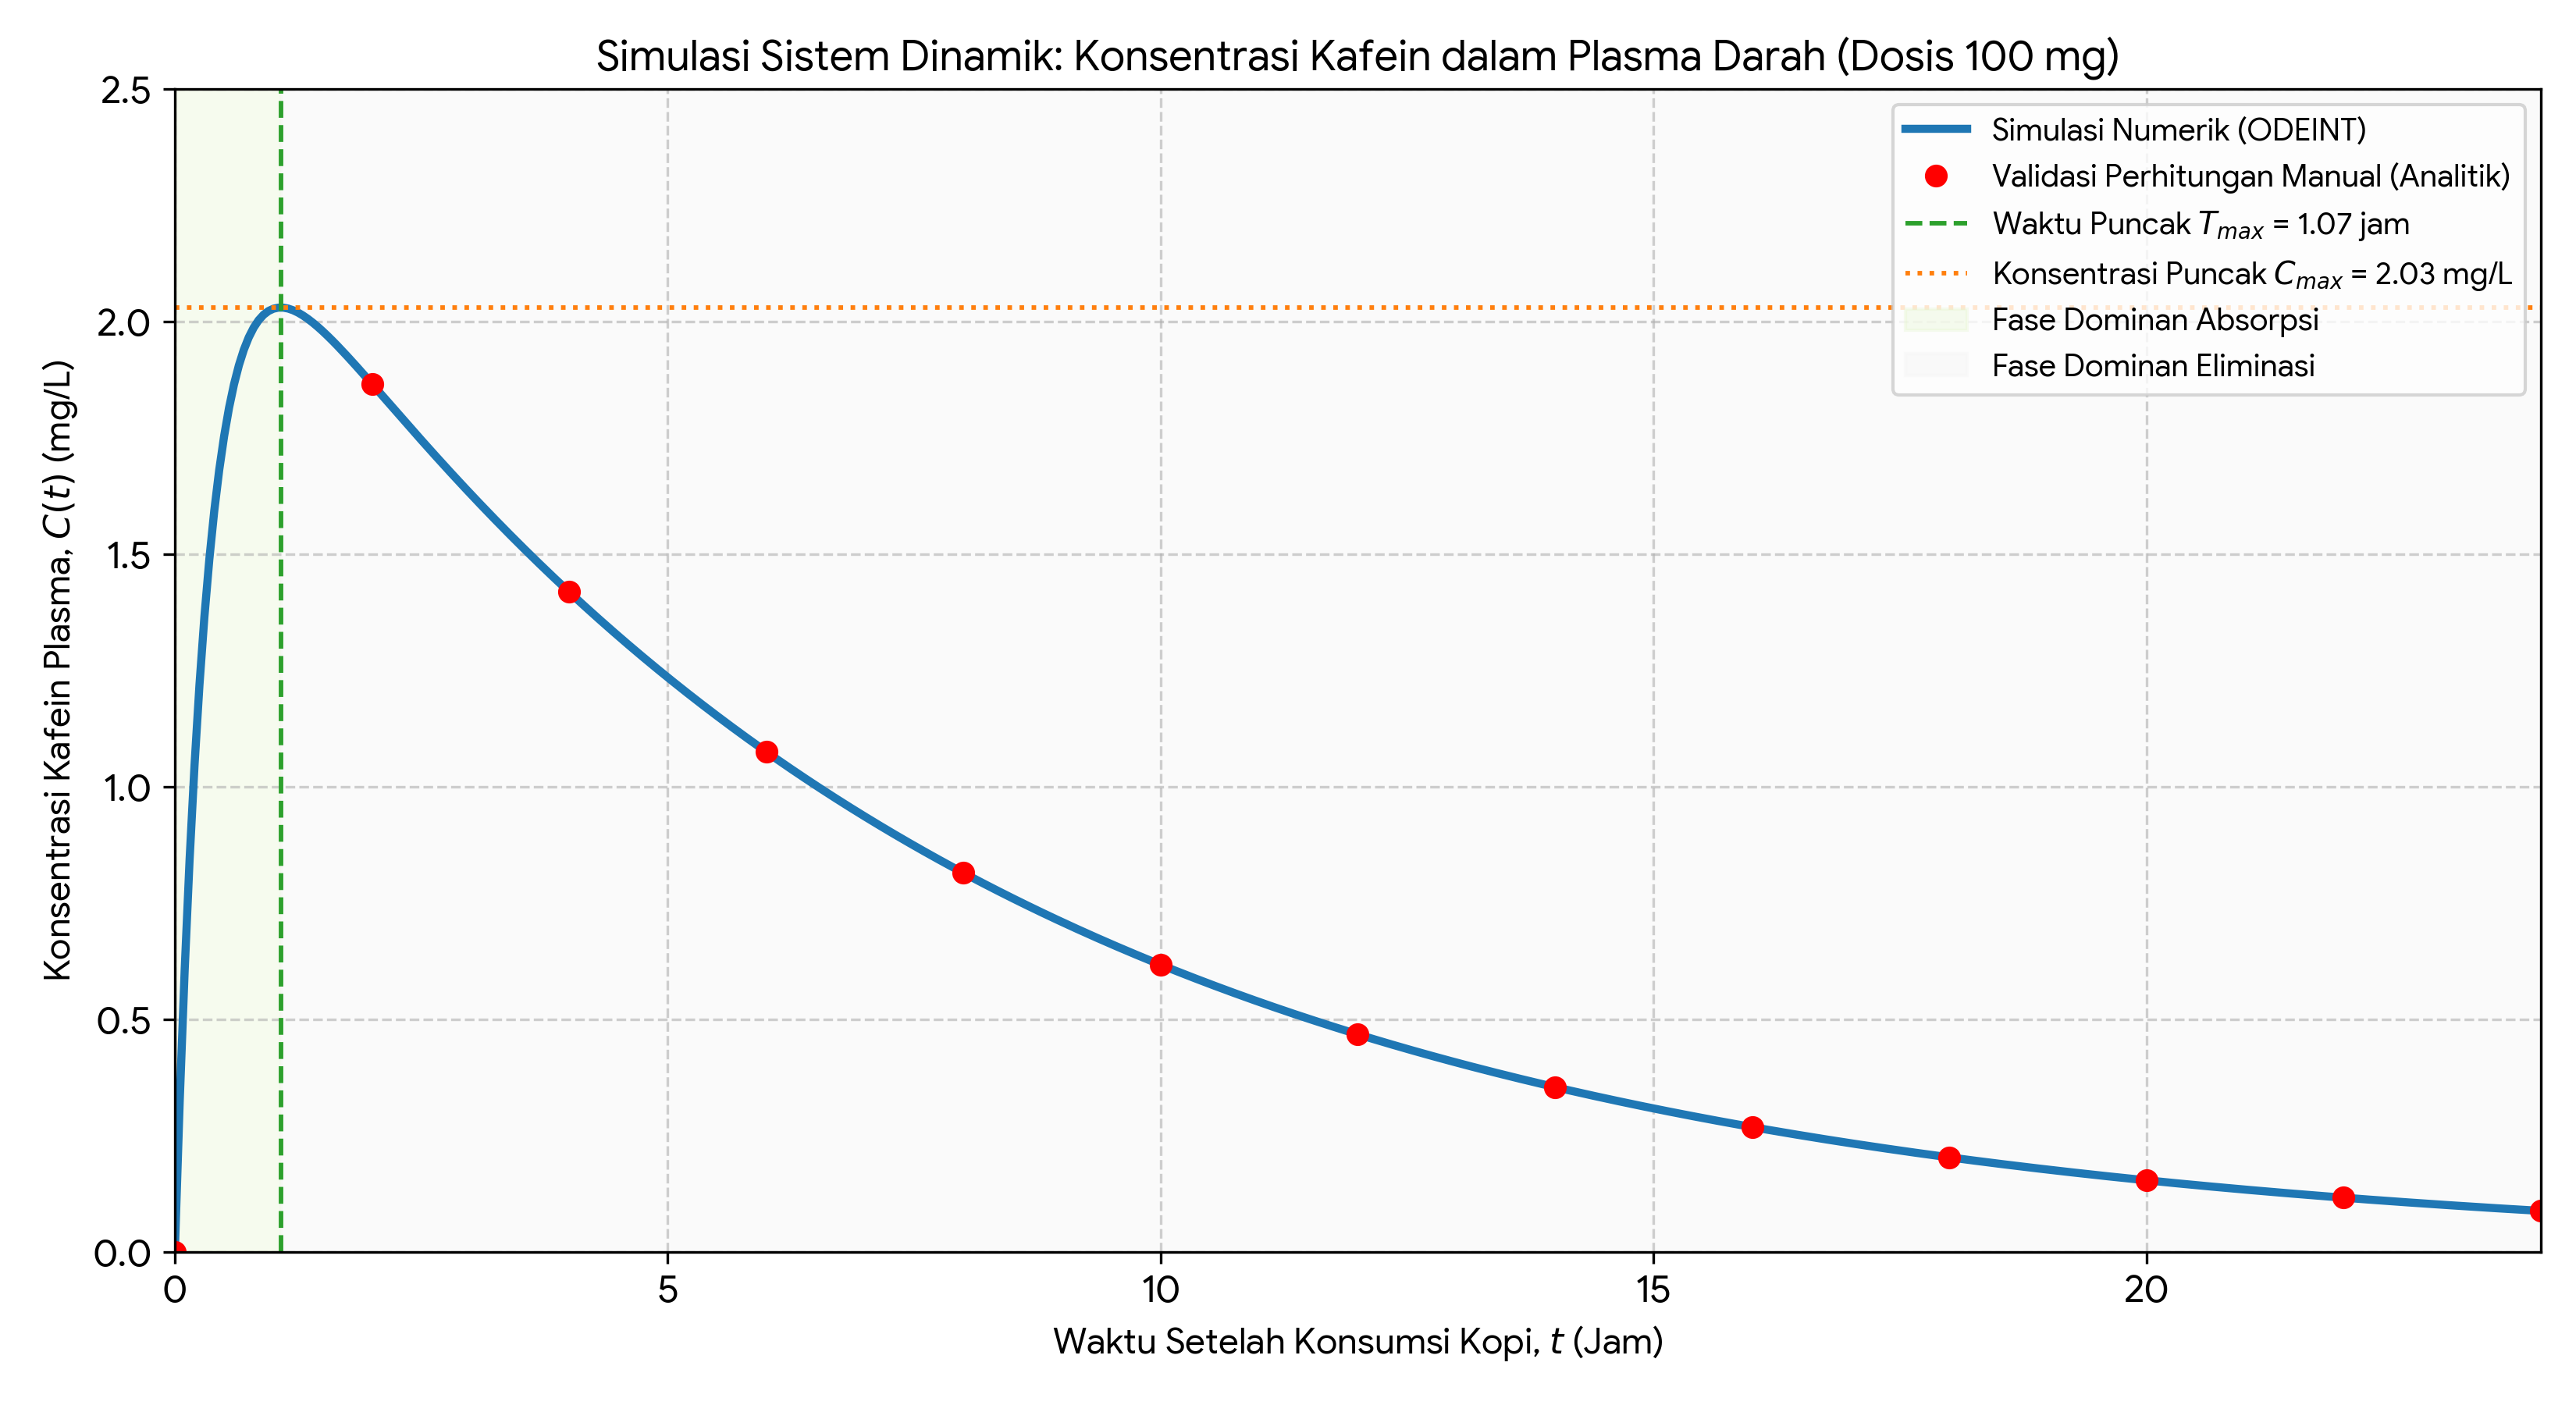

In [5]:
plt.figure(figsize=(11, 6))
plt.plot(t, C_num, color='#1f77b4', linewidth=2.5, label='Simulasi Numerik (ODEINT)')
plt.plot(t_cek, C_ana_cek, 'ro', markersize=6, label='Validasi Perhitungan Manual (Analitik)')
plt.axvline(x=t_max, color='#2ca02c', linestyle='--', linewidth=1.4, label=f'Waktu Puncak $T_{{max}}$ = {t_max:.2f} jam')
plt.axhline(y=c_max, color='#ff7f0e', linestyle=':', linewidth=1.4, label=f'Konsentrasi Puncak $C_{{max}}$ = {c_max:.2f} mg/L')
plt.axvspan(0, t_max, color='#e6f5d0', alpha=0.35, label='Fase Dominan Absorpsi')
plt.axvspan(t_max, 24, color='#f7f7f7', alpha=0.5, label='Fase Dominan Eliminasi')

plt.title('Simulasi Sistem Dinamik: Konsentrasi Kafein dalam Plasma Darah (Dosis 100 mg)', fontsize=13, fontweight='bold')
plt.xlabel('Waktu Setelah Konsumsi Kopi, $t$ (Jam)', fontsize=11)
plt.ylabel('Konsentrasi Kafein Plasma, $C(t)$ (mg/L)', fontsize=11)
plt.xlim(0, 24)
plt.ylim(0, 2.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.savefig('grafik_1_konsentrasi_kafein_utama.png', dpi=300)
plt.show()

### Grafik 2: Dinamika Kompartemen Saluran Cerna ($A_{\text{gut}}$) vs Plasma Darah ($C(t)$)

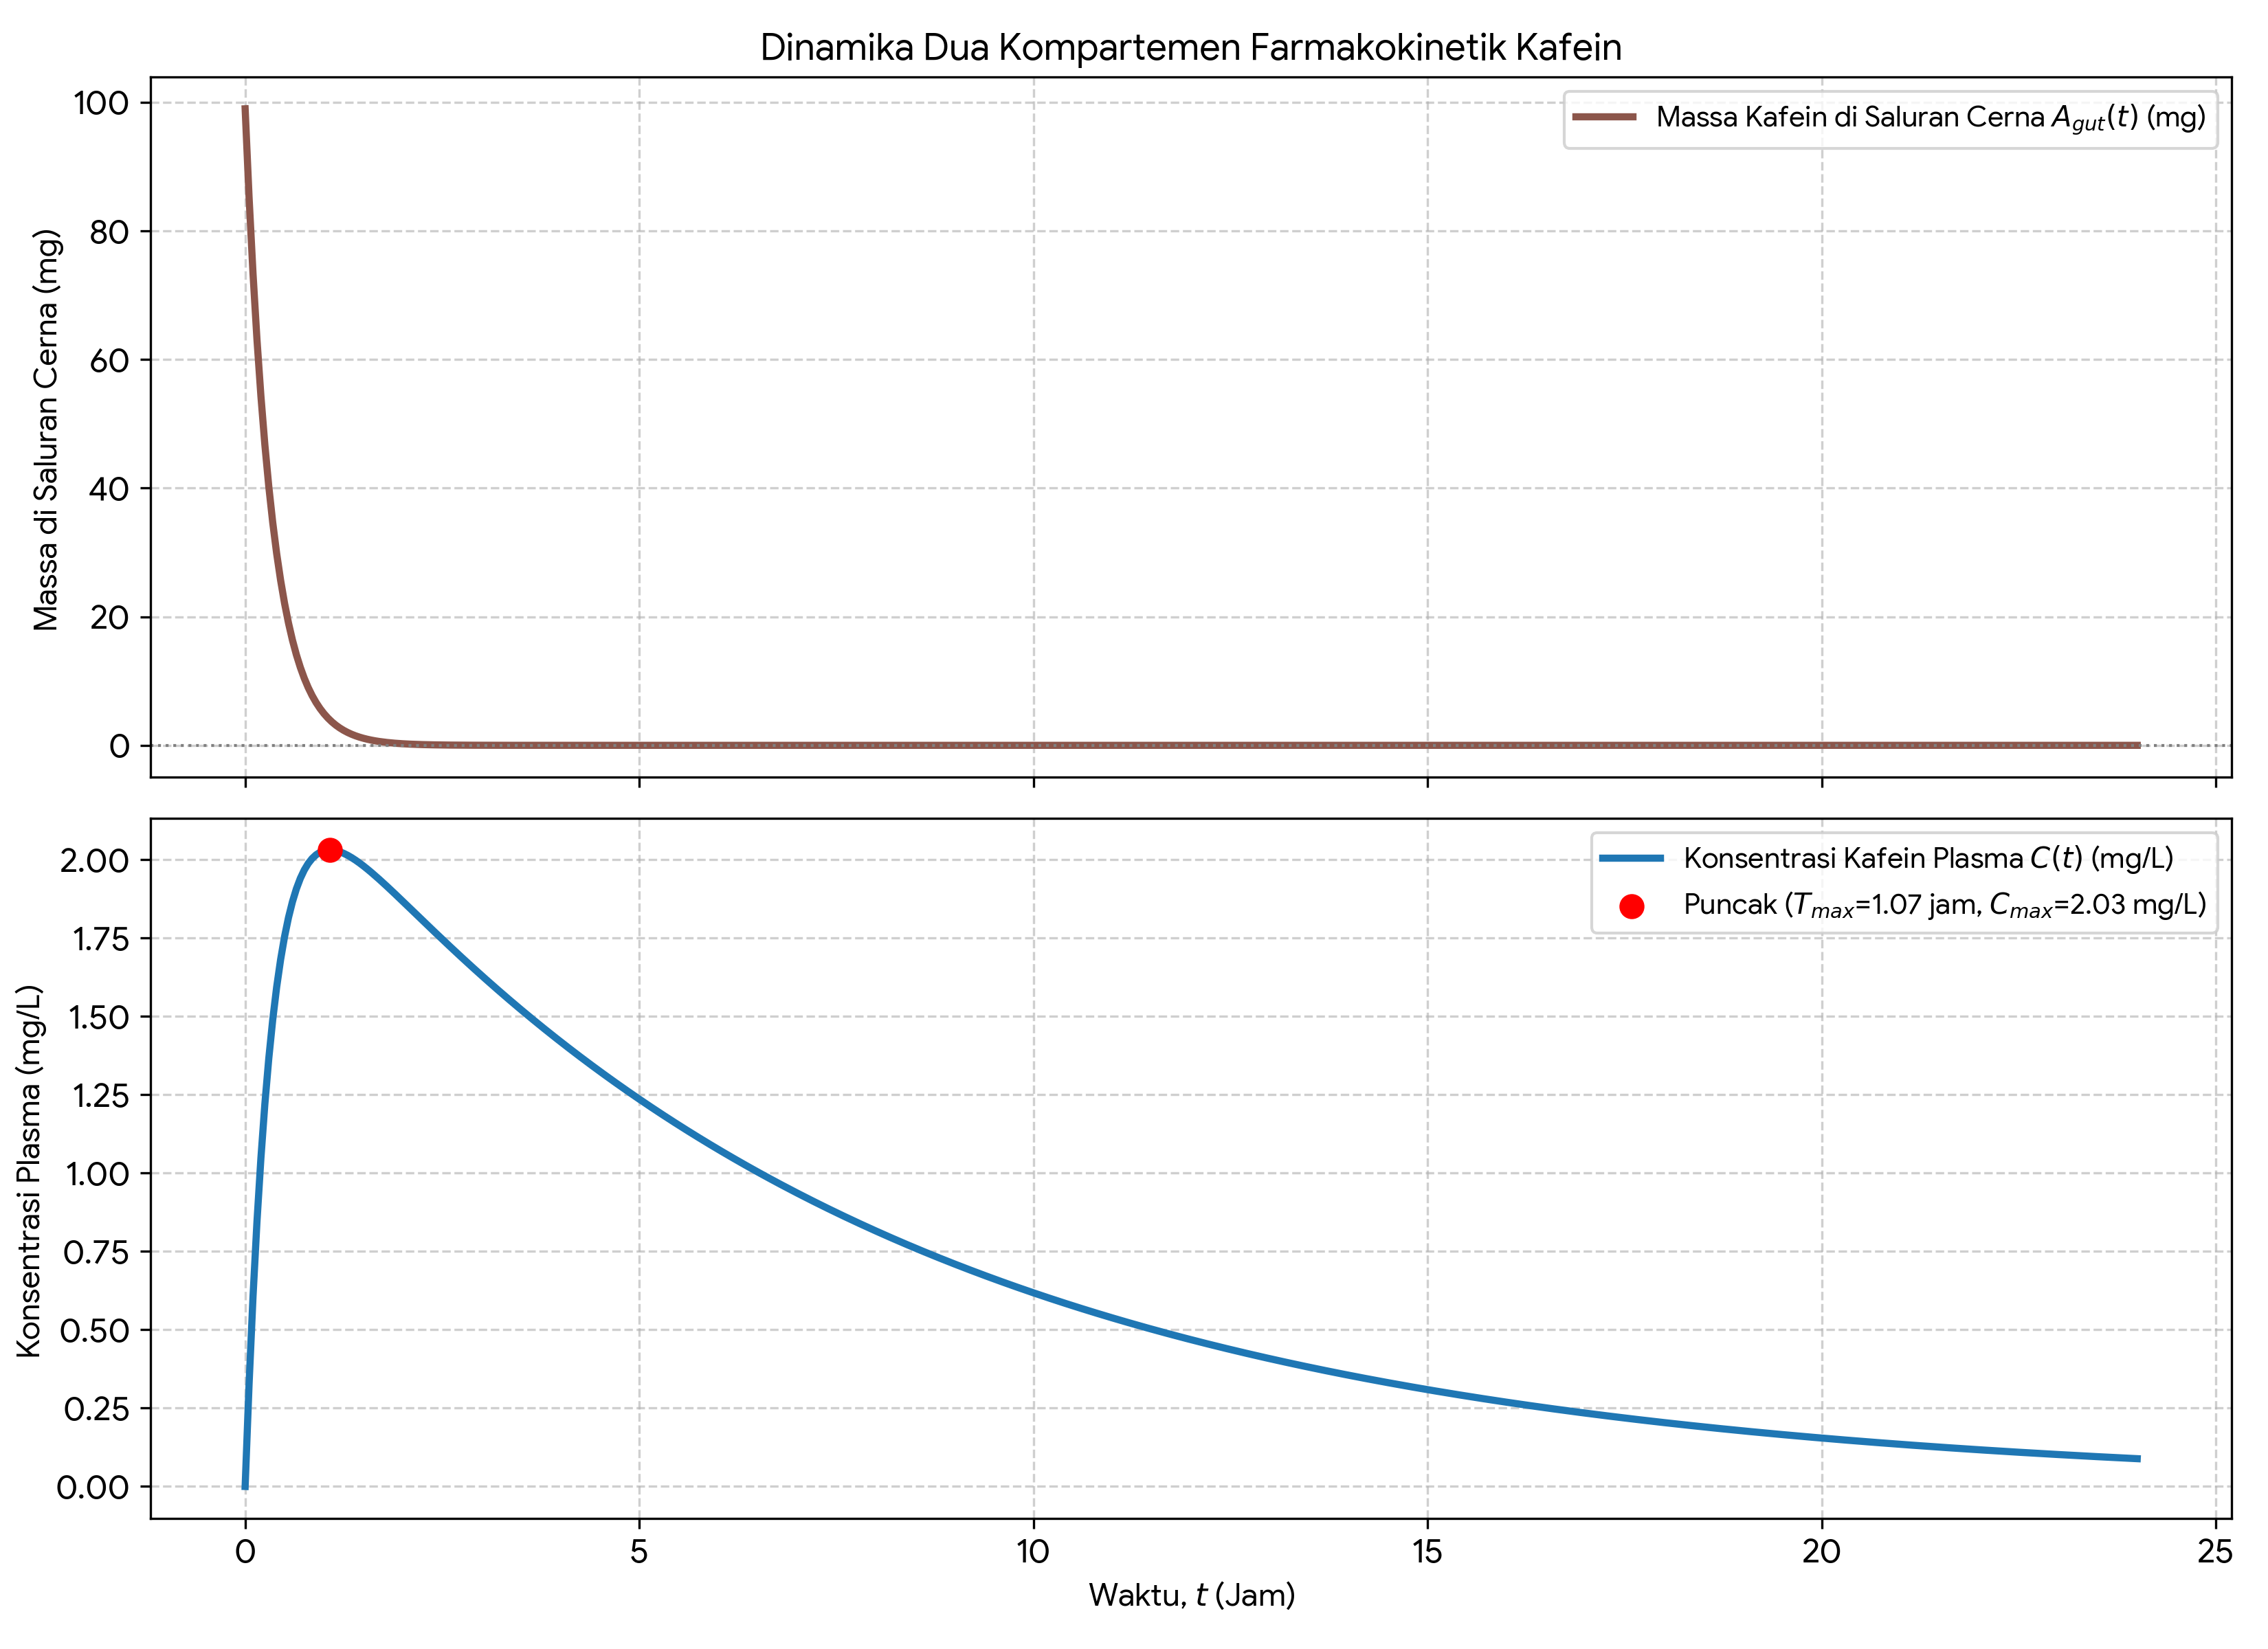

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

ax1.plot(t, A_num, color='#8c564b', linewidth=2.5, label='Massa Kafein di Saluran Cerna $A_{gut}(t)$ (mg)')
ax1.axhline(y=0, color='gray', linestyle=':', linewidth=1)
ax1.set_ylabel('Massa di Saluran Cerna (mg)', fontsize=11)
ax1.set_title('Dinamika Dua Kompartemen Farmakokinetik Kafein', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right', frameon=True)

ax2.plot(t, C_num, color='#1f77b4', linewidth=2.5, label='Konsentrasi Kafein Plasma $C(t)$ (mg/L)')
ax2.scatter([t_max], [c_max], color='red', zorder=5, s=60, label=f'Puncak ($T_{{max}}$={t_max:.2f} jam, $C_{{max}}$={c_max:.2f} mg/L)')
ax2.set_xlabel('Waktu, $t$ (Jam)', fontsize=11)
ax2.set_ylabel('Konsentrasi Plasma (mg/L)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('grafik_2_dua_kompartemen.png', dpi=300)
plt.show()

### Grafik 3: Analisis Sensitivitas Kecepatan Metabolisme ($t_{1/2}$)

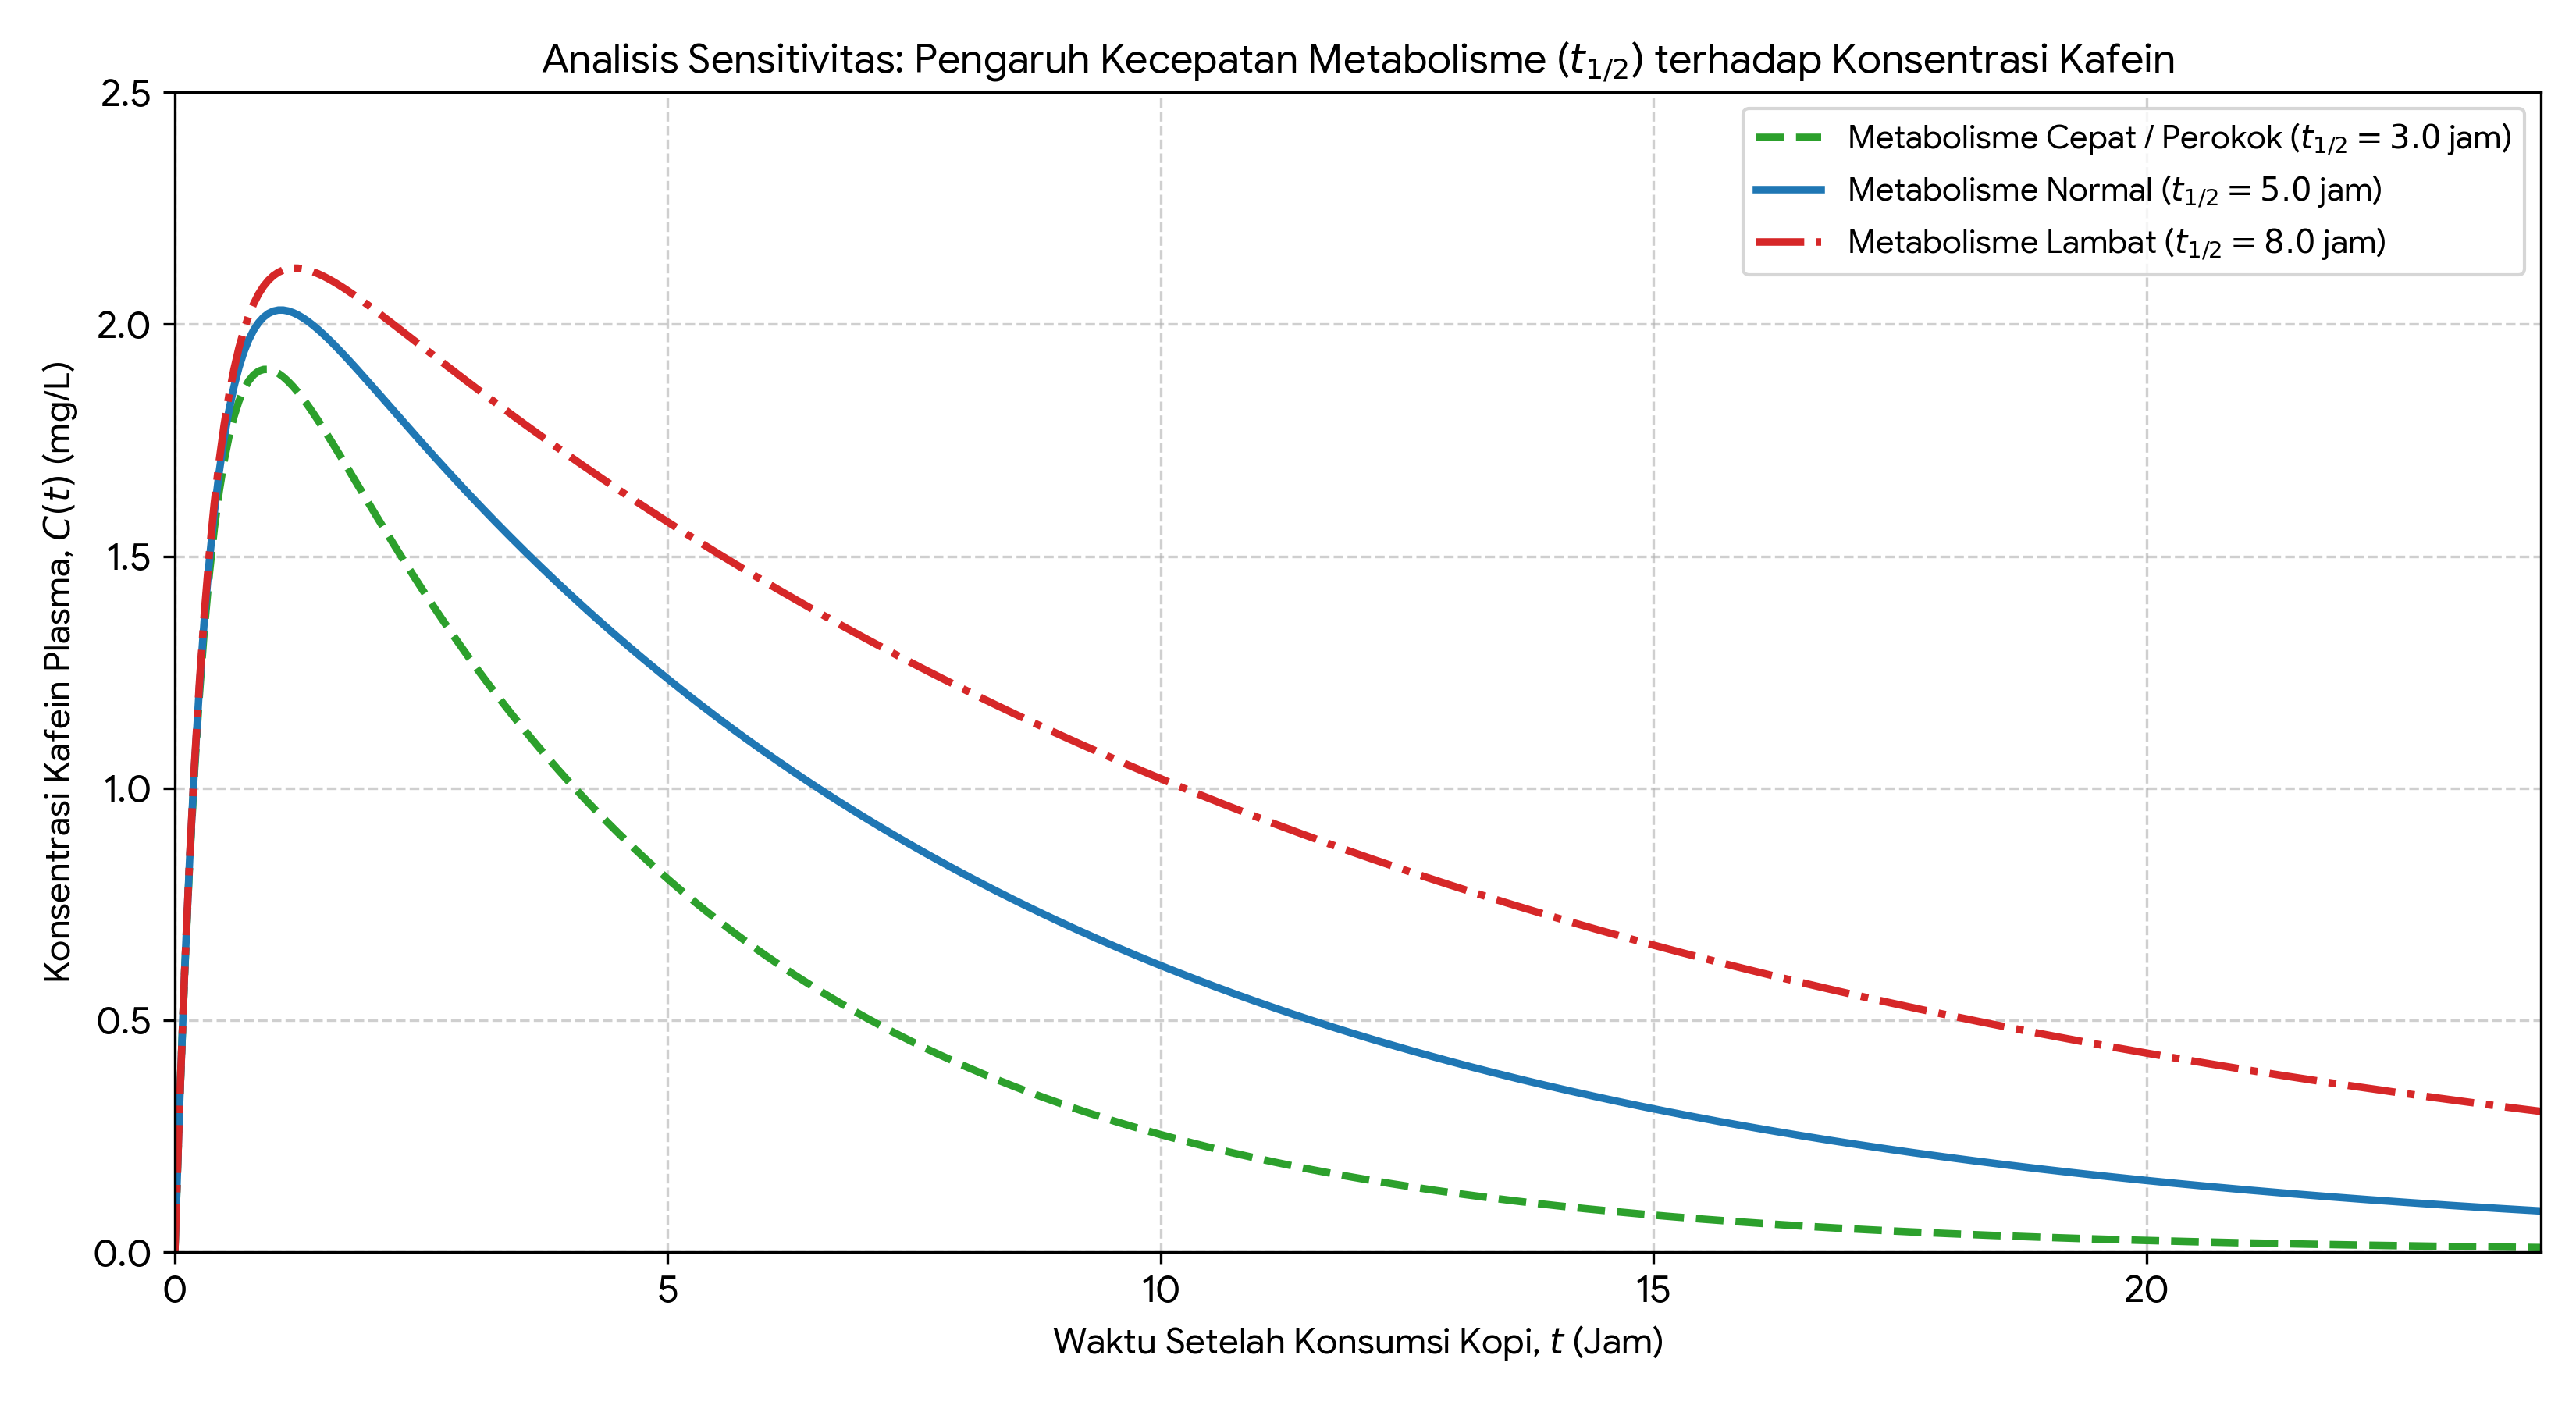

In [7]:
plt.figure(figsize=(11, 6))
skenario_t_half = [
    (3.0, 'Metabolisme Cepat / Perokok ($t_{1/2} = 3.0$ jam)', '#2ca02c', '--'),
    (5.0, 'Metabolisme Normal ($t_{1/2} = 5.0$ jam)', '#1f77b4', '-'),
    (8.0, 'Metabolisme Lambat ($t_{1/2} = 8.0$ jam)', '#d62728', '-.')
]

for th, lbl, clr, ls in skenario_t_half:
    ke_var = np.log(2) / th
    sol_var = odeint(model_kafein, y0, t, args=(ka, ke_var, Vd))
    plt.plot(t, sol_var[:, 1], color=clr, linestyle=ls, linewidth=2.3, label=lbl)

plt.title('Analisis Sensitivitas: Pengaruh Kecepatan Metabolisme ($t_{1/2}$) terhadap Konsentrasi Kafein', fontsize=12.5, fontweight='bold')
plt.xlabel('Waktu Setelah Konsumsi Kopi, $t$ (Jam)', fontsize=11)
plt.ylabel('Konsentrasi Kafein Plasma, $C(t)$ (mg/L)', fontsize=11)
plt.xlim(0, 24)
plt.ylim(0, 2.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig('grafik_3_sensitivitas_metabolisme.png', dpi=300)
plt.show()